# TCC ML - Extinção
#### João Avila Harduin - 00332195
#### Kauã Cordeiro Cavalheiro - 00331660
#### Luan Bonasorte Capella - 00332061
-----

## Professora orientadora
#### Edith Ranzini

## Notebook 3 de 3 — Fronteira de Decisão e Limpeza

Investiga espécies "Not Threatened" próximas da fronteira com "Threatened" e testa duas formas de removê-las do treino (ENN e remoção direta), com e sem ajuste de hiperparâmetros. As comparações usam a tabela consolidada do notebook 02 (`resultados/resultados_modelagem.csv`).

| Notebook | Conteúdo |
|---|---|
| `01_construcao_dataset.ipynb` | Seções 1–5: aquisição, análise exploratória, construção do dataset e pré-processamento |
| `02_modelagem.ipynb` | Seções 6–10: Random Forest, SVM e XGBoost, SMOTE × SMOTENC, ajuste de hiperparâmetros e tabela consolidada |
| `03_fronteira_e_limpeza.ipynb` | Seções 11–13: diagnóstico de fronteira, limpeza (ENN e Passo 1) e Teste 4 |

### Sumário deste notebook

Setup e dados
11. Diagnóstico de Fronteira (Passo 1)
12. Limpeza das Amostras de Fronteira (Testes 2 e 3)
13. Teste 4 — Ajuste de Hiperparâmetros nos 3 Cenários (13.5: exportação)

> No Colab, use o painel **Índice** (ícone ☰ à esquerda) para navegar entre as seções. O código reutilizado fica em `src/tcc_extincao/`; as correções metodológicas estão descritas no `README.md`.

## Setup

Prepara o ambiente (no Colab, clona o repositório e instala o `matplotlib-venn`) e importa o pacote `tcc_extincao`.

> **Tempo de execução:** os `GridSearchCV` levam horas no Colab gratuito. Por padrão, os melhores hiperparâmetros salvos em `resultados/buscas/` são reaproveitados e só o modelo final é treinado (o resultado é o mesmo). Para refazer as buscas, descomente `config.REFAZER_BUSCAS = True` na célula de imports.

In [1]:
# No Colab, clona o repositório (os dados são baixados do Google Drive pelo
# próprio notebook); localmente, usa a pasta do repositório
import sys
from pathlib import Path

REPO_URL = 'https://github.com/kcac1108/tcc-ml-extincao.git'

if 'google.colab' in sys.modules:
    RAIZ = Path('/content/tcc-ml-extincao')
    if not RAIZ.exists():
        !git clone -q {REPO_URL} {RAIZ}
    %pip install -q matplotlib-venn
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'tcc_extincao').exists())

sys.path.insert(0, str(RAIZ / 'src'))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

from tcc_extincao import config, dados, modelos, avaliacao, graficos, preprocessamento as prep
from tcc_extincao.config import RANDOM_STATE

# Para refazer os GridSearchCV (horas no Colab gratuito), descomente a linha abaixo
# config.REFAZER_BUSCAS = True

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 80)

### Dados

Reconstruímos o dataset e o split treino/teste exatamente como no notebook 01, e carregamos os resultados do notebook 02.

In [3]:
# Mesmo dataset e mesmo split treino/teste do notebook 01 (RANDOM_STATE fixo)
dataset = dados.construir_dataset()
df, colunas_systems = prep.codificar(dataset)
X, y = prep.separar_X_y(df)
X_treino, X_teste, y_treino, y_teste = prep.dividir_treino_teste(X, y)

# Versões sem redlistCategory (data leakage), usadas na maior parte dos experimentos
X_treino_base, X_teste_base = prep.sem_redlist(X_treino), prep.sem_redlist(X_teste)
colunas_categoricas, indices_categoricos = prep.colunas_categoricas(X_treino_base, colunas_systems)

print(f'Treino: {X_treino.shape}  |  Teste: {X_teste.shape}')

# Resultados do notebook 02, na ordem em que foram registrados
resultados_experimentos = pd.read_csv(config.RESULTADOS_MODELAGEM_PATH).to_dict('records')

assessments.csv já existe, download pulado.
Rodentia_gbif.csv já existe, download pulado.
taxonomy.csv já existe, download pulado.


Dataset: 721 espécies x 30 colunas
Treino: (576, 344)  |  Teste: (145, 344)


## 11. Diagnóstico de Fronteira (Passo 1) — amostras "Not Threatened" na fronteira de decisão

Hipótese levantada pelo professor: existem espécies rotuladas como **"Not Threatened"** (sem risco de extinção) que, pelas suas características numéricas, estão muito próximas da fronteira com a classe **"Threatened"**. Essas amostras ambíguas prejudicam o treino dos modelos.

Para identificar quais espécies são essas, repetimos muitas vezes o seguinte experimento (variação do teste do professor, mas testando todas as espécies "Not Threatened", não só uma subamostra fixa):

1. Dividir os dados em treino/teste usando validação cruzada estratificada, repetida com várias sementes aleatórias.
2. Fazer **undersampling só no treino** (reduzir "Not Threatened" ao tamanho de "Threatened"), mantendo o teste com a distribuição original dos dados.
3. Treinar um Random Forest (mesma configuração usada no resto do notebook) e registrar, para cada espécie "Not Threatened" que caiu no teste, se ela foi classificada corretamente.

Repetindo esse processo muitas vezes, cada espécie "Not Threatened" é testada várias vezes, em combinações de treino diferentes. Calculamos a **taxa de erro por espécie**: quantas vezes ela foi testada vs. quantas vezes o modelo errou. Espécies com taxa de erro alta são as principais suspeitas de estarem na fronteira entre as duas classes.

> **Correção:** o Random Forest deste diagnóstico usa as features **sem** `redlistCategory` (antes a coluna era incluída, e o modelo acertava a classe pelo vazamento). A imputação pela mediana é feita dentro de cada fold.

In [4]:
N_REPEATS_FRONTEIRA = 20   # repetições da validação cruzada (sementes diferentes)
N_SPLITS = 5               # folds por repetição -> 100 treinos de RF no total

# redlistCategory fica de fora: o rótulo é derivado dela (data leakage)
rastreio = avaliacao.rastrear_fronteira(prep.sem_redlist(X), y, dataset.loc[X.index, 'scientificName'].values,
                                        n_repeticoes=N_REPEATS_FRONTEIRA, n_splits=N_SPLITS)

print(f"Total de treinos de Random Forest executados: {N_REPEATS_FRONTEIRA * N_SPLITS}")
print(f"Cada espécie 'Not Threatened' foi testada, em média, "
      f"{rastreio.loc[rastreio['label'] == 0, 'vezes_no_teste'].mean():.1f} vezes.")

Total de treinos de Random Forest executados: 100
Cada espécie 'Not Threatened' foi testada, em média, 20.0 vezes.


### 11.1 Espécies "Not Threatened" mais suspeitas de estarem na fronteira

Ordenamos pela taxa de erro (e, como critério de desempate, por quantas vezes a espécie foi testada — mais testes dão mais confiança na taxa).

In [5]:
suspeitas = rastreio[(rastreio['label'] == 0) & (rastreio['vezes_no_teste'] > 0)] \
    .sort_values(['taxa_erro', 'vezes_no_teste'], ascending=[False, False])

print(f"Espécies 'Not Threatened' com taxa de erro > 0: {(suspeitas['taxa_erro'] > 0).sum()} de {len(suspeitas)}")
suspeitas.head(30)

Espécies 'Not Threatened' com taxa de erro > 0: 236 de 661


,scientificName,label,vezes_no_teste,vezes_errado,taxa_erro
3,Anomalurus pelii,0,20,20,1.00
8,Plagiodontia aedium,0,20,20,1.00
15,Microcavia shiptoni,0,20,20,1.00
27,Ctenomys magellanicus,0,20,20,1.00
30,Ctenomys pearsoni,0,20,20,1.00
39,Dasyprocta coibae,0,20,20,1.00
42,Laonastes aenigmamus,0,20,20,1.00
46,Scarturus euphratica,0,20,20,1.00
116,Rhinosciurus laticaudatus,0,20,20,1.00
121,Lariscus hosei,0,20,20,1.00


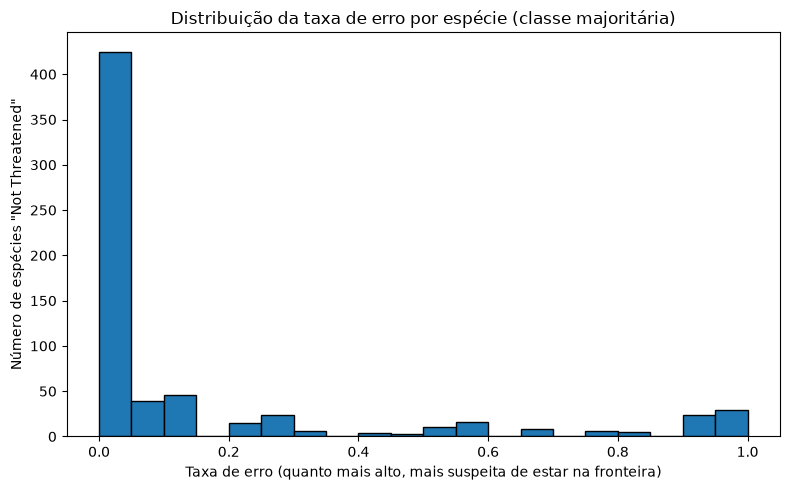

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(rastreio.loc[rastreio['label'] == 0, 'taxa_erro'], bins=20, edgecolor='black')
plt.xlabel('Taxa de erro (quanto mais alto, mais suspeita de estar na fronteira)')
plt.ylabel('Número de espécies "Not Threatened"')
plt.title('Distribuição da taxa de erro por espécie (classe majoritária)')
plt.tight_layout()
plt.show()

## 12. Limpeza das Amostras de Fronteira

### 12.1 Teste 2 — Limpeza com ENN

Ideia: em vez de só diagnosticar (Passo 1), aplicamos o **Edited Nearest Neighbours (ENN)** diretamente no conjunto de treino, **antes** do balanceamento com SMOTENC. O ENN olha, para cada espécie "Not Threatened" do treino, seus 3 vizinhos mais próximos no espaço de features; se todos os vizinhos forem "Threatened", a espécie é removida por estar no território errado.

Importante: o balanceamento continua sendo o SMOTENC que já usamos (metodologicamente superior ao SMOTE tradicional, ver diagnóstico de contaminação categórica), só mudou o que entra nele: em vez do treino bruto, entra o treino já limpo pelo ENN. O `X_teste_base`/`y_teste` permanece intocado, igual a todas as outras comparações.

In [7]:
enn = EditedNearestNeighbours(n_neighbors=3, kind_sel='all')
X_treino_base_limpo, y_treino_limpo = enn.fit_resample(X_treino_base, y_treino)

print("--- ANTES DO ENN (treino) ---")
print(y_treino.value_counts())
print("\n--- DEPOIS DO ENN (treino) ---")
print(y_treino_limpo.value_counts())

n_removidas = len(X_treino_base) - len(X_treino_base_limpo)
print(f"\n{n_removidas} espécies 'Not Threatened' removidas do treino por estarem na fronteira (ENN).")

# O fit_resample do imblearn reseta o índice do resultado (vira 0..n-1).
# Usamos sample_indices_ (posições no array ORIGINAL que foram mantidas)
# para recuperar corretamente quais espécies foram removidas.
idx_mantidos = X_treino_base.index[enn.sample_indices_]
idx_removidos = X_treino_base.index.difference(idx_mantidos)
especies_removidas_enn = set(dataset.loc[idx_removidos, 'scientificName'])

# Comparação com a lista de suspeitas do Passo 1 (restrita às espécies que
# estão no conjunto de treino atual, já que o ENN só pode remover dali)
suspeitas_no_treino = set(dataset.loc[X_treino_base.index.intersection(
    rastreio[rastreio['taxa_erro'] > 0].index
), 'scientificName'])

intersecao = suspeitas_no_treino & especies_removidas_enn

print(f"\nEspécies suspeitas no Passo 1 que estão no treino atual: {len(suspeitas_no_treino)}")
print(f"Espécies removidas pelo ENN: {len(especies_removidas_enn)}")
print(f"Espécies em comum entre os dois métodos: {len(intersecao)}")
if especies_removidas_enn:
    print(f"% das removidas pelo ENN que também apareceram como suspeitas no Passo 1: "
          f"{100 * len(intersecao) / len(especies_removidas_enn):.1f}%")

--- ANTES DO ENN (treino) ---
label
0    528
1     48
Name: count, dtype: int64

--- DEPOIS DO ENN (treino) ---
label
0    458
1     48
Name: count, dtype: int64

70 espécies 'Not Threatened' removidas do treino por estarem na fronteira (ENN).

Espécies suspeitas no Passo 1 que estão no treino atual: 185
Espécies removidas pelo ENN: 70
Espécies em comum entre os dois métodos: 44
% das removidas pelo ENN que também apareceram como suspeitas no Passo 1: 62.9%


In [8]:
smote_nc_limpo = SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)
X_treino_balanceado_nc_limpo, y_treino_balanceado_nc_limpo = smote_nc_limpo.fit_resample(
    X_treino_base_limpo, y_treino_limpo
)

print("--- DEPOIS DO ENN + SMOTENC (Dados de Treino Balanceados) ---")
print(y_treino_balanceado_nc_limpo.value_counts())

--- DEPOIS DO ENN + SMOTENC (Dados de Treino Balanceados) ---
label
0    458
1    458
Name: count, dtype: int64


In [9]:
rf_model_nc_limpo = RandomForestClassifier(random_state=RANDOM_STATE)
y_pred_rf_nc_limpo, tempo_treino_rf_nc_limpo = modelos.treinar_e_avaliar(
    rf_model_nc_limpo, X_treino_balanceado_nc_limpo, y_treino_balanceado_nc_limpo, X_teste_base, y_teste,
    'Random Forest (ENN + SMOTENC)')

### Random Forest (ENN + SMOTENC) ###

Tempo de treinamento: 0.0884 segundos

Relatório de Classificação Random Forest (ENN + SMOTENC):
              precision    recall  f1-score   support

           0       0.98      0.91      0.94       133
           1       0.43      0.75      0.55        12

    accuracy                           0.90       145
   macro avg       0.70      0.83      0.74       145
weighted avg       0.93      0.90      0.91       145

Matriz de Confusão Random Forest (ENN + SMOTENC):
 [[121  12]
 [  3   9]]
Acurácia Random Forest (ENN + SMOTENC): 0.8966


In [10]:
svm_model_nc_limpo = Pipeline([('scaler', StandardScaler()), ('modelo', SVC(random_state=RANDOM_STATE))])
y_pred_svm_nc_limpo, tempo_treino_svm_nc_limpo = modelos.treinar_e_avaliar(
    svm_model_nc_limpo, X_treino_balanceado_nc_limpo, y_treino_balanceado_nc_limpo, X_teste_base, y_teste,
    'SVM (ENN + SMOTENC)')

### SVM (ENN + SMOTENC) ###

Tempo de treinamento: 0.0261 segundos

Relatório de Classificação SVM (ENN + SMOTENC):
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       133
           1       0.15      0.17      0.16        12

    accuracy                           0.86       145
   macro avg       0.54      0.54      0.54       145
weighted avg       0.86      0.86      0.86       145

Matriz de Confusão SVM (ENN + SMOTENC):
 [[122  11]
 [ 10   2]]
Acurácia SVM (ENN + SMOTENC): 0.8552


In [11]:
xgb_model_nc_limpo = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
y_pred_xgb_nc_limpo, tempo_treino_xgb_nc_limpo = modelos.treinar_e_avaliar(
    xgb_model_nc_limpo, X_treino_balanceado_nc_limpo, y_treino_balanceado_nc_limpo, X_teste_base, y_teste,
    'XGBoost (ENN + SMOTENC)')

### XGBoost (ENN + SMOTENC) ###



Tempo de treinamento: 0.1703 segundos

Relatório de Classificação XGBoost (ENN + SMOTENC):
              precision    recall  f1-score   support

           0       0.98      0.89      0.93       133
           1       0.38      0.75      0.50        12

    accuracy                           0.88       145
   macro avg       0.68      0.82      0.71       145
weighted avg       0.93      0.88      0.89       145

Matriz de Confusão XGBoost (ENN + SMOTENC):
 [[118  15]
 [  3   9]]
Acurácia XGBoost (ENN + SMOTENC): 0.8759


### 12.2 Teste 3 — Remoção direta das espécies do Passo 1 (sem ENN)

Em vez de usar a regra geométrica do ENN, removemos diretamente do treino as espécies "Not Threatened" que o **Passo 1** já havia apontado como suspeitas (taxa de erro > 0 na validação cruzada repetida com Random Forest), restrito às que caem no conjunto de treino atual.

**Ressalva metodológica importante**: diferente do ENN (que só olha para o treino, sem nenhuma informação do teste), a lista do Passo 1 foi construída usando validação cruzada sobre o dataset **inteiro** (incluindo, em algumas repetições, espécies que aqui estão no conjunto de teste). Isso não vaza o rótulo do teste diretamente, mas é uma diferença metodológica real frente ao ENN, vale deixar isso registrado no texto do TCC ao reportar esta comparação.

In [12]:
idx_suspeitas_no_treino = X_treino_base.index.intersection(rastreio[rastreio['taxa_erro'] > 0].index)

X_treino_base_limpo_p1 = X_treino_base.drop(index=idx_suspeitas_no_treino)
y_treino_limpo_p1 = y_treino.drop(index=idx_suspeitas_no_treino)

print(f"Espécies removidas (suspeitas do Passo 1 presentes no treino): {len(idx_suspeitas_no_treino)}")
print("\n--- ANTES (treino) ---")
print(y_treino.value_counts())
print("\n--- DEPOIS da remoção (Passo 1) (treino) ---")
print(y_treino_limpo_p1.value_counts())

Espécies removidas (suspeitas do Passo 1 presentes no treino): 185

--- ANTES (treino) ---
label
0    528
1     48
Name: count, dtype: int64

--- DEPOIS da remoção (Passo 1) (treino) ---
label
0    343
1     48
Name: count, dtype: int64


In [13]:
smote_nc_p1 = SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)
X_treino_balanceado_nc_p1, y_treino_balanceado_nc_p1 = smote_nc_p1.fit_resample(
    X_treino_base_limpo_p1, y_treino_limpo_p1
)

print("--- DEPOIS da remoção (Passo 1) + SMOTENC (Dados de Treino Balanceados) ---")
print(y_treino_balanceado_nc_p1.value_counts())

--- DEPOIS da remoção (Passo 1) + SMOTENC (Dados de Treino Balanceados) ---
label
0    343
1    343
Name: count, dtype: int64


In [14]:
rf_model_nc_p1 = RandomForestClassifier(random_state=RANDOM_STATE)
y_pred_rf_nc_p1, tempo_treino_rf_nc_p1 = modelos.treinar_e_avaliar(
    rf_model_nc_p1, X_treino_balanceado_nc_p1, y_treino_balanceado_nc_p1, X_teste_base, y_teste,
    'Random Forest (Remoção Passo 1 + SMOTENC)')

### Random Forest (Remoção Passo 1 + SMOTENC) ###

Tempo de treinamento: 0.0779 segundos

Relatório de Classificação Random Forest (Remoção Passo 1 + SMOTENC):
              precision    recall  f1-score   support

           0       0.99      0.83      0.90       133
           1       0.32      0.92      0.48        12

    accuracy                           0.83       145
   macro avg       0.66      0.87      0.69       145
weighted avg       0.94      0.83      0.87       145

Matriz de Confusão Random Forest (Remoção Passo 1 + SMOTENC):
 [[110  23]
 [  1  11]]
Acurácia Random Forest (Remoção Passo 1 + SMOTENC): 0.8345


In [15]:
svm_model_nc_p1 = Pipeline([('scaler', StandardScaler()), ('modelo', SVC(random_state=RANDOM_STATE))])
y_pred_svm_nc_p1, tempo_treino_svm_nc_p1 = modelos.treinar_e_avaliar(
    svm_model_nc_p1, X_treino_balanceado_nc_p1, y_treino_balanceado_nc_p1, X_teste_base, y_teste,
    'SVM (Remoção Passo 1 + SMOTENC)')

### SVM (Remoção Passo 1 + SMOTENC) ###

Tempo de treinamento: 0.0240 segundos

Relatório de Classificação SVM (Remoção Passo 1 + SMOTENC):
              precision    recall  f1-score   support

           0       0.94      0.85      0.89       133
           1       0.20      0.42      0.27        12

    accuracy                           0.81       145
   macro avg       0.57      0.63      0.58       145
weighted avg       0.88      0.81      0.84       145

Matriz de Confusão SVM (Remoção Passo 1 + SMOTENC):
 [[113  20]
 [  7   5]]
Acurácia SVM (Remoção Passo 1 + SMOTENC): 0.8138


In [16]:
xgb_model_nc_p1 = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
y_pred_xgb_nc_p1, tempo_treino_xgb_nc_p1 = modelos.treinar_e_avaliar(
    xgb_model_nc_p1, X_treino_balanceado_nc_p1, y_treino_balanceado_nc_p1, X_teste_base, y_teste,
    'XGBoost (Remoção Passo 1 + SMOTENC)')

### XGBoost (Remoção Passo 1 + SMOTENC) ###



Tempo de treinamento: 0.1108 segundos

Relatório de Classificação XGBoost (Remoção Passo 1 + SMOTENC):
              precision    recall  f1-score   support

           0       0.99      0.80      0.89       133
           1       0.30      0.92      0.45        12

    accuracy                           0.81       145
   macro avg       0.64      0.86      0.67       145
weighted avg       0.93      0.81      0.85       145

Matriz de Confusão XGBoost (Remoção Passo 1 + SMOTENC):
 [[107  26]
 [  1  11]]
Acurácia XGBoost (Remoção Passo 1 + SMOTENC): 0.8138


### 12.3 Comparação com a tabela consolidada

Adicionamos os três resultados (RF, SVM, XGBoost — todos sem tuning, pra comparar de forma justa com as linhas "SMOTENC" já existentes) na mesma tabela consolidada da Seção 10 (notebook 02).

In [17]:
registrar = avaliacao.registrar_resultado

registrar(resultados_experimentos, 'Random Forest', 'SMOTENC + ENN', tuning=False,
          y_true=y_teste, y_pred=y_pred_rf_nc_limpo, tempo_treino=tempo_treino_rf_nc_limpo)
registrar(resultados_experimentos, 'SVM', 'SMOTENC + ENN', tuning=False,
          y_true=y_teste, y_pred=y_pred_svm_nc_limpo, tempo_treino=tempo_treino_svm_nc_limpo)
registrar(resultados_experimentos, 'XGBoost', 'SMOTENC + ENN', tuning=False,
          y_true=y_teste, y_pred=y_pred_xgb_nc_limpo, tempo_treino=tempo_treino_xgb_nc_limpo)

registrar(resultados_experimentos, 'Random Forest', 'SMOTENC + Passo1', tuning=False,
          y_true=y_teste, y_pred=y_pred_rf_nc_p1, tempo_treino=tempo_treino_rf_nc_p1)
registrar(resultados_experimentos, 'SVM', 'SMOTENC + Passo1', tuning=False,
          y_true=y_teste, y_pred=y_pred_svm_nc_p1, tempo_treino=tempo_treino_svm_nc_p1)
registrar(resultados_experimentos, 'XGBoost', 'SMOTENC + Passo1', tuning=False,
          y_true=y_teste, y_pred=y_pred_xgb_nc_p1, tempo_treino=tempo_treino_xgb_nc_p1)

df_resultados = avaliacao.tabela_resultados(resultados_experimentos)
print(f"Total de experimentos registrados: {len(df_resultados)}\n")
df_resultados.round(4)

Total de experimentos registrados: 20



,modelo,balanceamento,tuning,acuracia,precisao,recall,f1,tempo_treino_s
0,Random Forest,Original — COM redlistCategory (leakage proposital),Sim,0.9931,1.0000,0.9167,0.9565,38.7412
1,XGBoost,SMOTENC,Sim,0.9310,0.5625,0.7500,0.6429,195.5185
2,Random Forest,SMOTENC,Sim,0.9172,0.5000,0.8333,0.6250,327.2438
3,Random Forest,SMOTE,Sim,0.8897,0.4167,0.8333,0.5556,53.4092
4,Random Forest,SMOTENC + ENN,Não,0.8966,0.4286,0.7500,0.5455,0.0884
5,Random Forest,SMOTENC,Não,0.9172,0.5000,0.5833,0.5385,0.1004
6,Random Forest,SMOTE,Não,0.9103,0.4667,0.5833,0.5185,0.1046
7,Random Forest,SMOTE (StandardScaler),Não,0.9103,0.4667,0.5833,0.5185,0.1085
8,SVM,SMOTE (StandardScaler),Sim,0.8897,0.4000,0.6667,0.5000,2.1034
9,XGBoost,SMOTENC + ENN,Não,0.8759,0.3750,0.7500,0.5000,0.1703


### 12.4 Comparação direta: SMOTENC vs. SMOTENC + ENN vs. SMOTENC + Passo 1 (mesmo modelo, mesmo tuning)

A tabela consolidada acima mistura experimentos com tuning, sem tuning e com vazamento proposital — ordenada por F1, fica difícil enxergar o efeito isolado de cada método de limpeza. Abaixo comparamos **só o que varia é a limpeza aplicada antes do SMOTENC** (nenhuma, ENN, ou remoção direta das espécies do Passo 1), mantendo modelo e tuning fixos (sem tuning em todos), para isolar o efeito de cada abordagem.

In [18]:
comparacao_limpeza = avaliacao.filtrar_cenarios(df_resultados, tuning='Não')
comparacao_limpeza[['modelo', 'balanceamento', 'acuracia', 'precisao', 'recall', 'f1']].round(4)

,modelo,balanceamento,acuracia,precisao,recall,f1
0,Random Forest,SMOTENC,0.9172,0.5000,0.5833,0.5385
1,Random Forest,SMOTENC + ENN,0.8966,0.4286,0.7500,0.5455
2,Random Forest,SMOTENC + Passo1,0.8345,0.3235,0.9167,0.4783
3,SVM,SMOTENC,0.8621,0.1667,0.1667,0.1667
4,SVM,SMOTENC + ENN,0.8552,0.1538,0.1667,0.1600
5,SVM,SMOTENC + Passo1,0.8138,0.2000,0.4167,0.2703
6,XGBoost,SMOTENC,0.9034,0.4375,0.5833,0.5000
7,XGBoost,SMOTENC + ENN,0.8759,0.3750,0.7500,0.5000
8,XGBoost,SMOTENC + Passo1,0.8138,0.2973,0.9167,0.4490


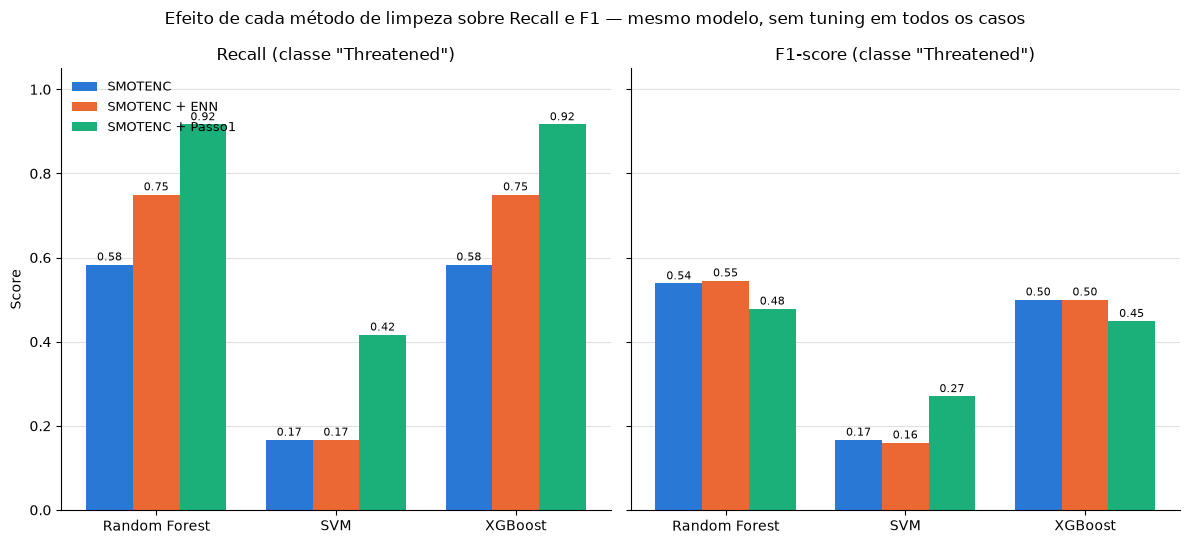

In [19]:
graficos.plot_comparacao_cenarios(
    comparacao_limpeza,
    'Efeito de cada método de limpeza sobre Recall e F1 — mesmo modelo, sem tuning em todos os casos')

## 13. Teste 4 — Ajuste de Hiperparâmetros nos 3 Cenários (SMOTENC vs. SMOTENC + ENN vs. SMOTENC + Passo 1)

Após a comparação direta com hiperparâmetros *default*, o próximo passo metodológico é avaliar se os métodos de limpeza de fronteira mantêm sua eficácia quando os modelos são devidamente otimizados.

Para isso, executamos o `GridSearchCV` (com as mesmas grades, validação cruzada 5-fold e métrica `f1` usadas nas etapas anteriores) para os cenários **SMOTENC + ENN** e **SMOTENC + Passo 1**. O cenário **SMOTENC puro** com tuning já foi executado nas Seções anteriores e será reaproveitado para compor a matriz comparativa completa.

> **Nota metodológica:** como nas Seções 7 a 9, a limpeza (ENN), o balanceamento (SMOTENC) e, no SVM, o `StandardScaler` ficam dentro de um `Pipeline`, ajustados em cada fold apenas com a parte de treino. No cenário **SMOTENC + Passo 1**, a remoção das espécies suspeitas acontece antes da busca, pois a lista vem do diagnóstico da Seção 11.

### 13.1 Ajuste de hiperparâmetros — SMOTENC + ENN

In [20]:
melhor_rf_nc_limpo, y_pred_rf_nc_limpo_otimizado, tempo_grid_rf_nc_limpo = modelos.rodar_grid(
    'rf_smotenc_enn',
    Pipeline([
        ('enn', EditedNearestNeighbours(n_neighbors=3, kind_sel='all')),
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('modelo', RandomForestClassifier(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_rf),
    X_treino_base, y_treino, X_teste_base, y_teste, 'Random Forest (SMOTENC + ENN)')

### GridSearchCV — Random Forest (SMOTENC + ENN) ###
Fitting 5 folds for each of 216 candidates, totalling 1080 fits



Tempo total de busca: 335.1499 segundos
Melhores hiperparâmetros encontrados: {'modelo__max_depth': None, 'modelo__max_features': 'log2', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 300}
Melhor score (F1, média da validação cruzada): 0.6411

Relatório de Classificação Random Forest (SMOTENC + ENN) (Otimizado):
              precision    recall  f1-score   support

           0       0.97      0.92      0.95       133
           1       0.44      0.67      0.53        12

    accuracy                           0.90       145
   macro avg       0.71      0.80      0.74       145
weighted avg       0.93      0.90      0.91       145

Matriz de Confusão Random Forest (SMOTENC + ENN) (Otimizado):
 [[123  10]
 [  4   8]]
Acurácia Random Forest (SMOTENC + ENN) (Otimizado): 0.9034


In [21]:
melhor_svm_nc_limpo, y_pred_svm_nc_limpo_otimizado, tempo_grid_svm_nc_limpo = modelos.rodar_grid(
    'svm_smotenc_enn',
    Pipeline([
        ('enn', EditedNearestNeighbours(n_neighbors=3, kind_sel='all')),
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('modelo', SVC(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_svm),
    X_treino_base, y_treino, X_teste_base, y_teste, 'SVM (SMOTENC + ENN, Escalado)')

### GridSearchCV — SVM (SMOTENC + ENN, Escalado) ###
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Tempo total de busca: 23.8783 segundos
Melhores hiperparâmetros encontrados: {'modelo__C': 100, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}
Melhor score (F1, média da validação cruzada): 0.4513

Relatório de Classificação SVM (SMOTENC + ENN, Escalado) (Otimizado):
              precision    recall  f1-score   support

           0       0.96      0.90      0.93       133
           1       0.35      0.58      0.44        12

    accuracy                           0.88       145
   macro avg       0.66      0.74      0.68       145
weighted avg       0.91      0.88      0.89       145

Matriz de Confusão SVM (SMOTENC + ENN, Escalado) (Otimizado):
 [[120  13]
 [  5   7]]
Acurácia SVM (SMOTENC + ENN, Escalado) (Otimizado): 0.8759


In [22]:
melhor_xgb_nc_limpo, y_pred_xgb_nc_limpo_otimizado, tempo_grid_xgb_nc_limpo = modelos.rodar_grid(
    'xgb_smotenc_enn',
    Pipeline([
        ('enn', EditedNearestNeighbours(n_neighbors=3, kind_sel='all')),
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('modelo', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')),
    ]),
    modelos.grade_pipeline(config.param_grid_xgb),
    X_treino_base, y_treino, X_teste_base, y_teste, 'XGBoost (SMOTENC + ENN)')

### GridSearchCV — XGBoost (SMOTENC + ENN) ###
Fitting 5 folds for each of 108 candidates, totalling 540 fits



Tempo total de busca: 179.7691 segundos
Melhores hiperparâmetros encontrados: {'modelo__colsample_bytree': 1.0, 'modelo__learning_rate': 0.2, 'modelo__max_depth': 5, 'modelo__n_estimators': 100, 'modelo__subsample': 0.8}
Melhor score (F1, média da validação cruzada): 0.5622

Relatório de Classificação XGBoost (SMOTENC + ENN) (Otimizado):
              precision    recall  f1-score   support

           0       0.99      0.89      0.94       133
           1       0.42      0.92      0.58        12

    accuracy                           0.89       145
   macro avg       0.71      0.90      0.76       145
weighted avg       0.94      0.89      0.91       145

Matriz de Confusão XGBoost (SMOTENC + ENN) (Otimizado):
 [[118  15]
 [  1  11]]
Acurácia XGBoost (SMOTENC + ENN) (Otimizado): 0.8897


### 13.2 Ajuste de hiperparâmetros — SMOTENC + Passo 1

In [23]:
melhor_rf_nc_p1, y_pred_rf_nc_p1_otimizado, tempo_grid_rf_nc_p1 = modelos.rodar_grid(
    'rf_smotenc_passo1',
    Pipeline([
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('modelo', RandomForestClassifier(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_rf),
    X_treino_base_limpo_p1, y_treino_limpo_p1, X_teste_base, y_teste, 'Random Forest (SMOTENC + Passo 1)')

### GridSearchCV — Random Forest (SMOTENC + Passo 1) ###
Fitting 5 folds for each of 216 candidates, totalling 1080 fits



Tempo total de busca: 262.5003 segundos
Melhores hiperparâmetros encontrados: {'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 4, 'modelo__min_samples_split': 10, 'modelo__n_estimators': 200}
Melhor score (F1, média da validação cruzada): 0.9527

Relatório de Classificação Random Forest (SMOTENC + Passo 1) (Otimizado):
              precision    recall  f1-score   support

           0       1.00      0.82      0.90       133
           1       0.33      1.00      0.50        12

    accuracy                           0.83       145
   macro avg       0.67      0.91      0.70       145
weighted avg       0.94      0.83      0.87       145

Matriz de Confusão Random Forest (SMOTENC + Passo 1) (Otimizado):
 [[109  24]
 [  0  12]]
Acurácia Random Forest (SMOTENC + Passo 1) (Otimizado): 0.8345


In [24]:
melhor_svm_nc_p1, y_pred_svm_nc_p1_otimizado, tempo_grid_svm_nc_p1 = modelos.rodar_grid(
    'svm_smotenc_passo1',
    Pipeline([
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('modelo', SVC(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_svm),
    X_treino_base_limpo_p1, y_treino_limpo_p1, X_teste_base, y_teste, 'SVM (SMOTENC + Passo 1, Escalado)')

### GridSearchCV — SVM (SMOTENC + Passo 1, Escalado) ###
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Tempo total de busca: 17.7358 segundos
Melhores hiperparâmetros encontrados: {'modelo__C': 10, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}
Melhor score (F1, média da validação cruzada): 0.7425

Relatório de Classificação SVM (SMOTENC + Passo 1, Escalado) (Otimizado):
              precision    recall  f1-score   support

           0       0.98      0.84      0.91       133
           1       0.32      0.83      0.47        12

    accuracy                           0.84       145
   macro avg       0.65      0.84      0.69       145
weighted avg       0.93      0.84      0.87       145

Matriz de Confusão SVM (SMOTENC + Passo 1, Escalado) (Otimizado):
 [[112  21]
 [  2  10]]
Acurácia SVM (SMOTENC + Passo 1, Escalado) (Otimizado): 0.8414


In [25]:
melhor_xgb_nc_p1, y_pred_xgb_nc_p1_otimizado, tempo_grid_xgb_nc_p1 = modelos.rodar_grid(
    'xgb_smotenc_passo1',
    Pipeline([
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('modelo', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')),
    ]),
    modelos.grade_pipeline(config.param_grid_xgb),
    X_treino_base_limpo_p1, y_treino_limpo_p1, X_teste_base, y_teste, 'XGBoost (SMOTENC + Passo 1)')

### GridSearchCV — XGBoost (SMOTENC + Passo 1) ###
Fitting 5 folds for each of 108 candidates, totalling 540 fits



Tempo total de busca: 136.9722 segundos
Melhores hiperparâmetros encontrados: {'modelo__colsample_bytree': 0.8, 'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__n_estimators': 100, 'modelo__subsample': 1.0}
Melhor score (F1, média da validação cruzada): 0.9500

Relatório de Classificação XGBoost (SMOTENC + Passo 1) (Otimizado):
              precision    recall  f1-score   support

           0       0.99      0.80      0.89       133
           1       0.30      0.92      0.45        12

    accuracy                           0.81       145
   macro avg       0.64      0.86      0.67       145
weighted avg       0.93      0.81      0.85       145

Matriz de Confusão XGBoost (SMOTENC + Passo 1) (Otimizado):
 [[107  26]
 [  1  11]]
Acurácia XGBoost (SMOTENC + Passo 1) (Otimizado): 0.8138


### 13.3 Consolidação dos resultados com tuning e comparação direta

Registramos os 6 novos experimentos otimizados na lista consolidada e estruturamos duas análises tabulares:
1. **Comparação Direta dos Modelos Otimizados:** desempenho de cada modelo nos 3 cenários de balanceamento (`SMOTENC`, `SMOTENC + ENN`, `SMOTENC + Passo1`) sob ajuste de hiperparâmetros (`tuning = Sim`).
2. **Impacto Marginal do Tuning ($\Delta$):** ganho ou variação de F1-score e Recall proporcionado pela busca de hiperparâmetros em relação aos parâmetros *default*.

In [26]:
# Registrar os 6 novos modelos otimizados na lista de resultados consolidada
registrar(resultados_experimentos, 'Random Forest', 'SMOTENC + ENN', tuning=True,
          y_true=y_teste, y_pred=y_pred_rf_nc_limpo_otimizado, tempo_treino=tempo_grid_rf_nc_limpo)
registrar(resultados_experimentos, 'SVM', 'SMOTENC + ENN', tuning=True,
          y_true=y_teste, y_pred=y_pred_svm_nc_limpo_otimizado, tempo_treino=tempo_grid_svm_nc_limpo)
registrar(resultados_experimentos, 'XGBoost', 'SMOTENC + ENN', tuning=True,
          y_true=y_teste, y_pred=y_pred_xgb_nc_limpo_otimizado, tempo_treino=tempo_grid_xgb_nc_limpo)

registrar(resultados_experimentos, 'Random Forest', 'SMOTENC + Passo1', tuning=True,
          y_true=y_teste, y_pred=y_pred_rf_nc_p1_otimizado, tempo_treino=tempo_grid_rf_nc_p1)
registrar(resultados_experimentos, 'SVM', 'SMOTENC + Passo1', tuning=True,
          y_true=y_teste, y_pred=y_pred_svm_nc_p1_otimizado, tempo_treino=tempo_grid_svm_nc_p1)
registrar(resultados_experimentos, 'XGBoost', 'SMOTENC + Passo1', tuning=True,
          y_true=y_teste, y_pred=y_pred_xgb_nc_p1_otimizado, tempo_treino=tempo_grid_xgb_nc_p1)

df_resultados = avaliacao.tabela_resultados(resultados_experimentos)
print(f"Total de experimentos registrados: {len(df_resultados)}\n")

# Tabela 1: Comparação direta apenas dos modelos OTIMIZADOS nos 3 cenários
comparacao_tuning = avaliacao.filtrar_cenarios(df_resultados, tuning='Sim')

print("--- COMPARAÇÃO DIRETA DOS MODELOS OTIMIZADOS (Tuning = Sim) ---")
comparacao_tuning[['modelo', 'balanceamento', 'acuracia', 'precisao', 'recall', 'f1', 'tempo_treino_s']].round(4)

Total de experimentos registrados: 26

--- COMPARAÇÃO DIRETA DOS MODELOS OTIMIZADOS (Tuning = Sim) ---


,modelo,balanceamento,acuracia,precisao,recall,f1,tempo_treino_s
0,Random Forest,SMOTENC,0.9172,0.5000,0.8333,0.6250,327.2438
1,Random Forest,SMOTENC + ENN,0.9034,0.4444,0.6667,0.5333,335.1499
2,Random Forest,SMOTENC + Passo1,0.8345,0.3333,1.0000,0.5000,262.5003
3,SVM,SMOTENC,0.8759,0.3500,0.5833,0.4375,31.1740
4,SVM,SMOTENC + ENN,0.8759,0.3500,0.5833,0.4375,23.8783
5,SVM,SMOTENC + Passo1,0.8414,0.3226,0.8333,0.4651,17.7358
6,XGBoost,SMOTENC,0.9310,0.5625,0.7500,0.6429,195.5185
7,XGBoost,SMOTENC + ENN,0.8897,0.4231,0.9167,0.5789,179.7691
8,XGBoost,SMOTENC + Passo1,0.8138,0.2973,0.9167,0.4490,136.9722


In [27]:
# Tabela 2: Impacto Marginal do Tuning (Delta F1 e Delta Recall: Otimizado - Default)
tabela_sem_tuning = comparacao_limpeza[['modelo', 'balanceamento', 'recall', 'f1']].rename(
    columns={'recall': 'recall_default', 'f1': 'f1_default'}
)
tabela_com_tuning = comparacao_tuning[['modelo', 'balanceamento', 'recall', 'f1']].rename(
    columns={'recall': 'recall_otimizado', 'f1': 'f1_otimizado'}
)

tabela_impacto = pd.merge(tabela_sem_tuning, tabela_com_tuning, on=['modelo', 'balanceamento'])
tabela_impacto['delta_recall'] = tabela_impacto['recall_otimizado'] - tabela_impacto['recall_default']
tabela_impacto['delta_f1'] = tabela_impacto['f1_otimizado'] - tabela_impacto['f1_default']

print("--- IMPACTO DO AJUSTE DE HIPERPARÂMETROS (Otimizado vs. Default) ---")
tabela_impacto[['modelo', 'balanceamento', 'recall_default', 'recall_otimizado', 'delta_recall', 'f1_default', 'f1_otimizado', 'delta_f1']].round(4)

--- IMPACTO DO AJUSTE DE HIPERPARÂMETROS (Otimizado vs. Default) ---


,modelo,balanceamento,recall_default,recall_otimizado,delta_recall,f1_default,f1_otimizado,delta_f1
0,Random Forest,SMOTENC,0.5833,0.8333,0.2500,0.5385,0.6250,0.0865
1,Random Forest,SMOTENC + ENN,0.7500,0.6667,-0.0833,0.5455,0.5333,-0.0121
2,Random Forest,SMOTENC + Passo1,0.9167,1.0000,0.0833,0.4783,0.5000,0.0217
3,SVM,SMOTENC,0.1667,0.5833,0.4167,0.1667,0.4375,0.2708
4,SVM,SMOTENC + ENN,0.1667,0.5833,0.4167,0.1600,0.4375,0.2775
5,SVM,SMOTENC + Passo1,0.4167,0.8333,0.4167,0.2703,0.4651,0.1948
6,XGBoost,SMOTENC,0.5833,0.7500,0.1667,0.5000,0.6429,0.1429
7,XGBoost,SMOTENC + ENN,0.7500,0.9167,0.1667,0.5000,0.5789,0.0789
8,XGBoost,SMOTENC + Passo1,0.9167,0.9167,0.0000,0.4490,0.4490,0.0000


### 13.4 Visualizações: comparação com tuning e efeito do ajuste

Abaixo geramos duas visualizações comparativas:
1. **Efeito de cada método de limpeza sobre Recall e F1 (com Tuning em todos os modelos):** espelho direto do gráfico da Seção 12.4, permitindo contrastar como as técnicas de balanceamento/limpeza se ordenam quando os modelos estão em sua melhor configuração.
2. **Efeito do Tuning (Default vs. Otimizado):** comparação pareada demonstrando o ganho de F1 obtido com a otimização em cada cenário.

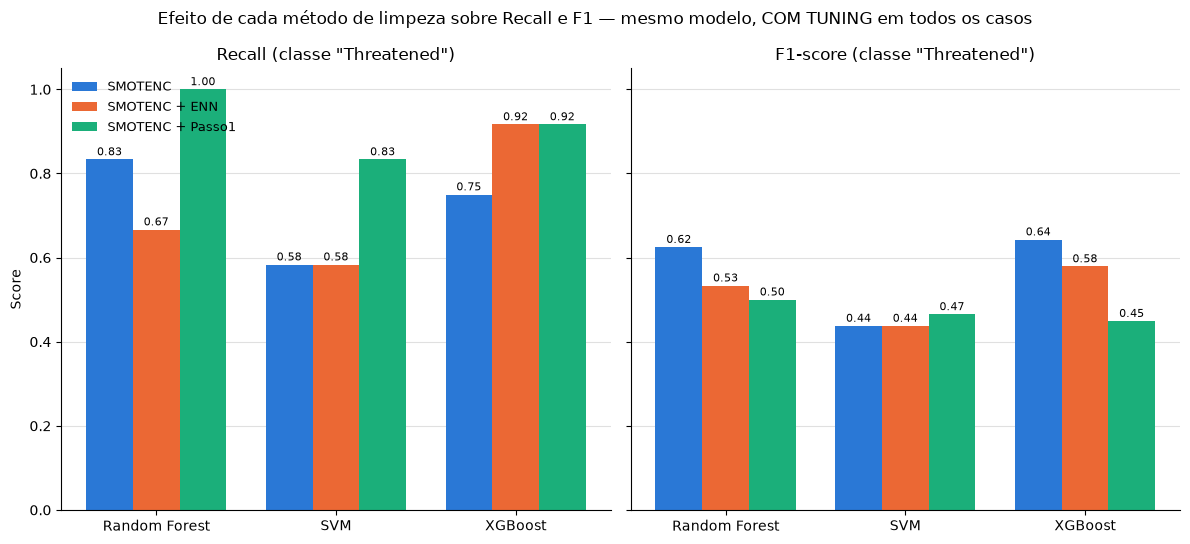

In [28]:
# Gráfico 1: Comparação Direta nos 3 cenários (COM TUNING em todos os casos)
graficos.plot_comparacao_cenarios(
    comparacao_tuning,
    'Efeito de cada método de limpeza sobre Recall e F1 — mesmo modelo, COM TUNING em todos os casos')

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


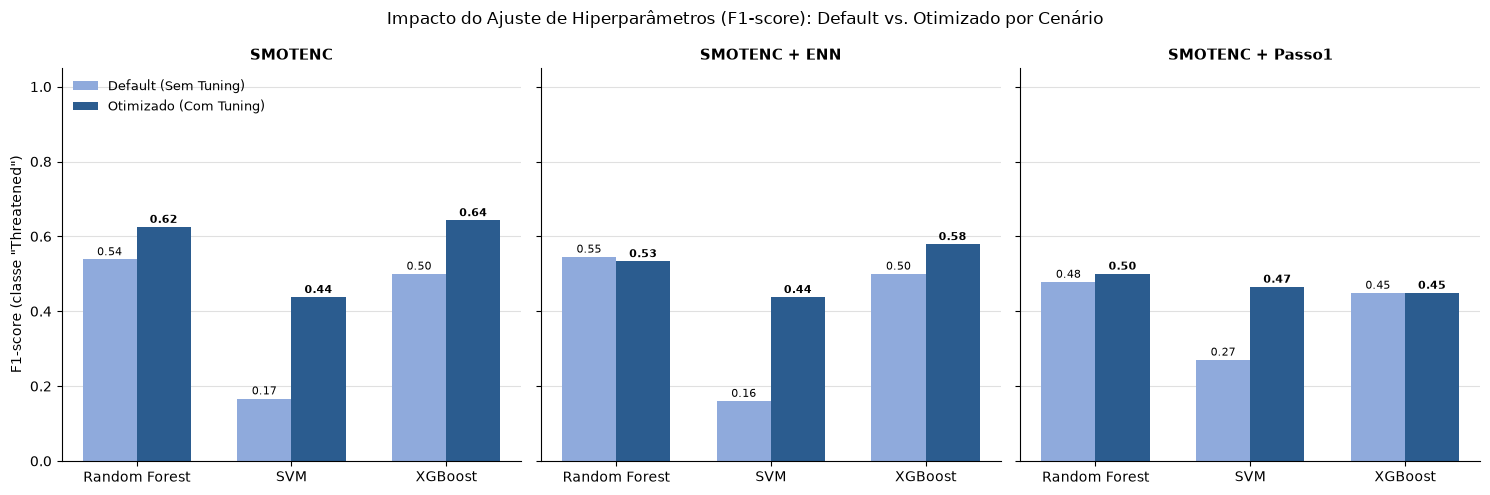

In [29]:
# Gráfico 2: Efeito do Tuning (Default vs. Otimizado) para cada Cenário de Balanceamento
graficos.plot_efeito_tuning(comparacao_limpeza, comparacao_tuning)

### 13.5 Exportação

A lista de espécies suspeitas (Seção 11.1) é salva em `data/final_data/`.

In [30]:
caminho_suspeitas = config.FINAL_DATA_DIR / 'especies_suspeitas_fronteira.csv'
suspeitas.to_csv(caminho_suspeitas, index=False)
print(f"Exportado: {caminho_suspeitas}  (shape: {suspeitas.shape})")

Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/especies_suspeitas_fronteira.csv  (shape: (661, 5))
